# Лабораторная работа № 3. Пропуски и выбросы

Цель работы — исследовать пропуски и потенциальные выбросы в данных о недвижимости,
обосновать способы обработки и оценить, как они изменили распределения признаков.

[Melbourne Housing Snapshot, Kaggle](https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot) · CC BY-NC-SA 4.0

## 2.1 Первичный анализ набора данных

Melbourne Housing Snapshot содержит 13 580 записей о сделках с жильём в Мельбурне за
2016–2017 годы. В исходном файле 21 столбец, включая адрес объекта и целевую переменную
$Price$ — цену в австралийских долларах. Характеристики объекта включают тип жилья,
число комнат, площадь дома и участка, а также год постройки. Местоположение задают
пригород, почтовый индекс, координаты и расстояние до делового центра. Дата продажи,
способ продажи и агент описывают сделку.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import StrMethodFormatter
from scipy import stats

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 115

data_dir = Path('.') if Path('melb_data.csv').is_file() else Path('Лаба3')
df_raw = pd.read_csv(data_dir / 'melb_data.csv')
df = df_raw.copy()

print(f'Строк и столбцов: {df.shape}')
df.head()

Строк и столбцов: (13580, 21)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [2]:
df.info()
df.nunique().sort_values().rename('Уникальных значений').to_frame()

<class 'pandas.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  str    
 1   Address        13580 non-null  str    
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  str    
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  str    
 6   SellerG        13580 non-null  str    
 7   Date           13580 non-null  str    
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  str    
 17  Lattitude      13580 non-null  float64
 18  Longtitude     13

,Уникальных значений
Type,3
Method,5
Regionname,8
Rooms,9
Bathroom,9
Car,11
Bedroom2,12
CouncilArea,33
Date,58
YearBuilt,144


| Семантический тип | Столбцы |
|---|---|
| Количественные непрерывные | `Price`, `Distance`, `Landsize`, `BuildingArea`, `Lattitude`, `Longtitude` |
| Количественные дискретные | `Rooms`, `Bedroom2`, `Bathroom`, `Car`, `Propertycount` |
| Временные | `YearBuilt` (год постройки), `Date` (дата продажи) |
| Номинальные | `Type`, `Method`, `Regionname`, `CouncilArea`, `Suburb`, `SellerG` |
| Идентификаторы | `Address` (адрес), `Postcode` (код местоположения, семантически категория) |

### Подозрительные значения

In [3]:
zero_lot = df['Landsize'].eq(0)
zero_area = df['BuildingArea'].eq(0)
early_year = df['YearBuilt'].lt(1800)

checks = pd.Series({
    'BuildingArea == 0': zero_area.sum(),
    'Landsize == 0': zero_lot.sum(),
    'YearBuilt < 1800': early_year.sum(),
    'Bedroom2 == 0': df['Bedroom2'].eq(0).sum(),
}, name='Наблюдений')
display(checks.to_frame())
display(df.loc[early_year, ['Suburb', 'Address', 'YearBuilt']])
df.loc[zero_lot, 'Type'].value_counts().rename('Нулевых Landsize').to_frame()

,Наблюдений
BuildingArea == 0,17
Landsize == 0,1939
YearBuilt < 1800,1
Bedroom2 == 0,16


,Suburb,Address,YearBuilt
9968,Mount Waverley,5 Armstrong St,1196.0


,Нулевых Landsize
Type,
u,1629
h,171
t,139


В `BuildingArea` найдено 17 нулей, а у дома по адресу 5 Armstrong St указан год
постройки 1196. По правилам гайда переводим эти 18 значений в пропуски. У `Landsize`
1 939 нулей, из них 1 629 (84,0 %) приходятся на тип `u`, для которого отсутствие
собственного участка правдоподобно. Нули в `Landsize` и 16 нулей в `Bedroom2`
сохраняем: они могут отражать особенности объекта или способа учёта.

In [4]:
df.loc[zero_area, 'BuildingArea'] = np.nan
df.loc[early_year, 'YearBuilt'] = np.nan
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')

num_cols = [
    'Price', 'Rooms', 'Distance', 'Bedroom2', 'Bathroom', 'Car',
    'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude', 'Propertycount',
]
cat_cols = ['Type', 'Method', 'Regionname', 'CouncilArea', 'Suburb', 'SellerG', 'Postcode', 'Address']
print(f"Период: {df['Date'].min():%d.%m.%Y}–{df['Date'].max():%d.%m.%Y}")

desc = df[num_cols].describe().T.rename(columns={'50%': 'median', '25%': 'Q1', '75%': 'Q3'})
desc[['min', 'max', 'mean', 'median', 'std', 'Q1', 'Q3']].round(2)

Период: 28.01.2016–23.09.2017


,min,max,mean,median,std,Q1,Q3
Price,85000.00,9000000.00,1075684.08,903000.0,639310.72,650000.00,1330000.00
Rooms,1.00,10.00,2.94,3.0,0.96,2.00,3.00
Distance,0.00,48.10,10.14,9.2,5.87,6.10,13.00
Bedroom2,0.00,20.00,2.91,3.0,0.97,2.00,3.00
Bathroom,0.00,8.00,1.53,1.0,0.69,1.00,2.00
Car,0.00,10.00,1.61,2.0,0.96,1.00,2.00
Landsize,0.00,433014.00,558.42,440.0,3990.67,177.00,651.00
BuildingArea,1.00,44515.00,152.33,126.0,541.61,93.00,174.00
YearBuilt,1830.00,2018.00,1964.78,1970.0,36.30,1940.00,1999.00
Lattitude,-38.18,-37.41,-37.81,-37.8,0.08,-37.86,-37.76


In [5]:
categories = []
for col in cat_cols:
    counts = df[col].dropna().value_counts().head(5)
    table = counts.rename('Число').rename_axis('Категория').reset_index()
    table.insert(0, 'Признак', col)
    table.insert(1, 'Уникальных', df[col].nunique())
    table['Доля от всех строк, %'] = (counts.to_numpy() / len(df) * 100).round(2)
    categories.append(table)

pd.concat(categories, ignore_index=True).set_index(['Признак', 'Уникальных', 'Категория'])

Число  \
Признак     Уникальных Категория                           
Type        3          h                            9449   
                       u                            3017   
                       t                            1114   
Method      5          S                            9022   
                       SP                           1703   
                       PI                           1564   
                       VB                           1199   
                       SA                             92   
Regionname  8          Southern Metropolitan        4695   
                       Northern Metropolitan        3890   
                       Western Metropolitan         2948   
                       Eastern Metropolitan         1471   
                       South-Eastern Metropolitan    450   
CouncilArea 33         Moreland                     1163   
                       Boroondara                   1160   
                       Moonee Valley                 997   
                       Darebin                       934   
                       Glen Eira                     848   
Suburb      314        Reservoir                     359   
                       Richmond                      260   
                       Bentleigh East                249   
                       Preston                       239   
                       Brunswick                     222   
SellerG     268        Nelson                       1565   
                       Jellis                       1316   
                       hockingstuart                1167   
                       Barry                        1011   
                       Ray                           701   
Postcode    198        3073.0                        359   
                       3020.0                        306   
                       3121.0                        292   
                       3040.0                        290   
                       3046.0                        284   
Address     13378      5 Charles St                    3   
                       13 Robinson St                  3   
                       5 Margaret St                   3   
                       28 Blair St                     3   
                       14 Arthur St                    3   

                                                   Доля от всех строк, %  
Признак     Уникальных Категория                                          
Type        3          h                                           69.58  
                       u                                           22.22  
                       t                                            8.20  
Method      5          S                                           66.44  
                       SP                                          12.54  
                       PI                                          11.52  
                       VB                                           8.83  
                       SA                                           0.68  
Regionname  8          Southern Metropolitan                       34.57  
                       Northern Metropolitan                       28.65  
                       Western Metropolitan                        21.71  
                       Eastern Metropolitan                        10.83  
                       South-Eastern Metropolitan                   3.31  
CouncilArea 33         Moreland                                     8.56  
                       Boroondara                                   8.54  
                       Moonee Valley                                7.34  
                       Darebin                                      6.88  
                       Glen Eira                                    6.24  
Suburb      314        Reservoir                                    2.64  
                       Richmond                                     1.91  


**Вывод.** Распределения цены и площади участка скошены вправо. Средняя цена
составляет 1 075 684 AUD при медиане 903 000 AUD. У `Landsize` среднее составляет
558,42 м² при медиане 440 м², а максимум достигает 433 014 м². Максимум
`BuildingArea` (44 515 м²) также сильно выделяется на фоне медианы 126 м².
Среди типов жилья доминирует `h` (69,58 %), среди способов продажи — `S`
(66,44 %), среди регионов — Southern Metropolitan (34,57 %). У известных
муниципалитетов нет столь явного лидера: Moreland и Boroondara составляют
8,56 % и 8,54 % от всех записей.

## 2.2 Анализ пропущенных значений

Считаем пропуски после перевода подозрительных значений `BuildingArea` и `YearBuilt` в `NaN`.

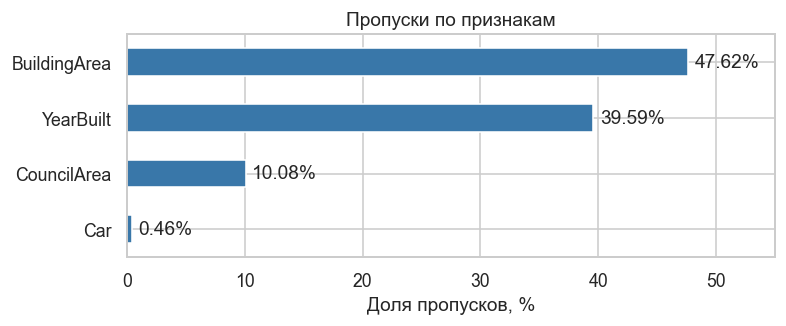

,Число пропусков,"Доля, %"
BuildingArea,6467,47.62
YearBuilt,5376,39.59
CouncilArea,1369,10.08
Car,62,0.46


In [6]:
miss_count = df.isna().sum().sort_values(ascending=False)
miss_count = miss_count[miss_count.gt(0)]
miss = miss_count / len(df)

ax = (miss * 100).plot.barh(figsize=(7, 3), color='#3977a9')
ax.set(xlabel='Доля пропусков, %', ylabel='', title='Пропуски по признакам')
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=4)
ax.set_xlim(0, 55)
plt.tight_layout()
plt.show()

pd.DataFrame({'Число пропусков': miss_count, 'Доля, %': (miss * 100).round(2)})

,Объектов,"Доля, %"
Пропусков в объекте,,
0,6194,45.61
1,2122,15.63
2,4670,34.39
3,564,4.15
4,30,0.22


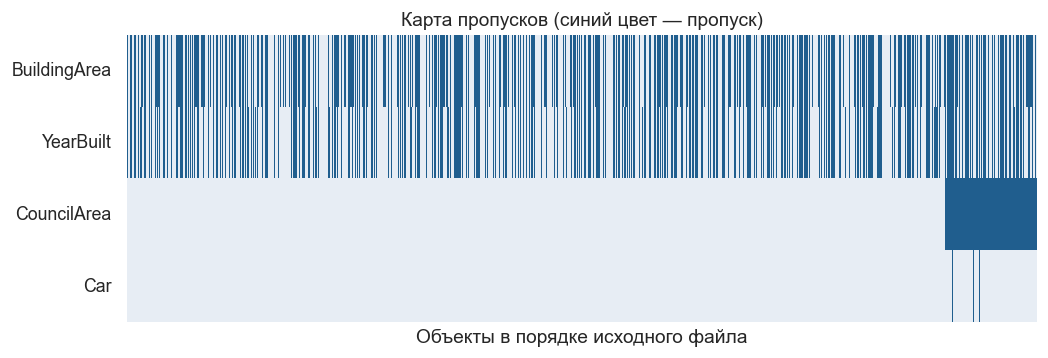

In [7]:
per_row = df.isna().sum(axis=1).value_counts().sort_index()
display(pd.DataFrame({
    'Объектов': per_row,
    'Доля, %': (per_row / len(df) * 100).round(2),
}).rename_axis('Пропусков в объекте'))

fig, ax = plt.subplots(figsize=(9, 3), layout='constrained')
sns.heatmap(df[miss.index].isna().T, cmap=['#e7edf4', '#205e8e'], cbar=False, xticklabels=False, ax=ax)
ax.set(title='Карта пропусков (синий цвет — пропуск)', xlabel='Объекты в порядке исходного файла', ylabel='')
plt.show()

In [8]:
for col in ['BuildingArea', 'YearBuilt', 'CouncilArea']:
    flag = df[col].isna().map({False: 'Есть значение', True: 'Пропуск'}).rename(col)
    display(df.groupby(flag)[['Price', 'Distance', 'Rooms']].median())
    display(pd.crosstab(df['Type'], flag, normalize='index').mul(100).round(2))

area_and_year_missing = df[['BuildingArea', 'YearBuilt']].isna().all(axis=1).sum()
print(f'Пропуски одновременно в BuildingArea и YearBuilt: {area_and_year_missing}')

flag = df['BuildingArea'].isna()
mw = stats.mannwhitneyu(df.loc[flag, 'Price'], df.loc[~flag, 'Price'], alternative='two-sided')
chi2 = stats.chi2_contingency(pd.crosstab(df['Type'], flag))
pd.DataFrame([
    ('Манна–Уитни (Price)', mw.statistic, mw.pvalue),
    ('χ² Пирсона (Type)', chi2.statistic, chi2.pvalue),
], columns=['Критерий для пропусков BuildingArea', 'Статистика', 'p-значение'])

,Price,Distance,Rooms
BuildingArea,,,
Есть значение,895000.0,9.2,3.0
Пропуск,917000.0,9.4,3.0


BuildingArea,Есть значение,Пропуск
Type,,
h,51.29,48.71
t,61.31,38.69
u,52.50,47.50


,Price,Distance,Rooms
YearBuilt,,,
Есть значение,880000.0,9.2,3.0
Пропуск,937750.0,9.7,3.0


YearBuilt,Есть значение,Пропуск
Type,,
h,57.22,42.78
t,68.40,31.60
u,67.45,32.55


,Price,Distance,Rooms
CouncilArea,,,
Есть значение,895000.0,9.2,3.0
Пропуск,1010000.0,12.3,3.0


CouncilArea,Есть значение,Пропуск
Type,,
h,86.82,13.18
t,93.81,6.19
u,98.18,1.82


Пропуски одновременно в BuildingArea и YearBuilt: 5103


,Критерий для пропусков BuildingArea,Статистика,p-значение
0,Манна–Уитни (Price),2.355919e+07,1.423342e-02
1,χ² Пирсона (Type),4.017284e+01,1.890507e-09


**Вывод.** Основные пропуски сосредоточены в `BuildingArea` (47,62 %) и
`YearBuilt` (39,59 %). Оба значения отсутствуют у 5 103 объектов. Полностью
заполнены 6 194 строки (45,61 %). Пропуски `CouncilArea` на карте сгущаются
к концу исходного файла, а медианное расстояние до центра у таких объектов
выше (12,3 км против 9,2 км).

У строк с пропуском `BuildingArea` медианная цена 917 000 AUD, у остальных —
895 000 AUD. Двусторонний тест Манна–Уитни дал $p=0{,}0142$. Доля пропусков
составляет 48,71 % для типа `h` и 38,69 % для `t`. Критерий $\chi^2$ для
связи с типом жилья дал $p=1{,}89\cdot10^{-9}$. При $\alpha=0{,}05$ результаты
дают основание отвергнуть MCAR для `BuildingArea`. Наблюдаемая зависимость
от типа и цены согласуется с гипотезой MAR. Если вероятность пропуска зависит
также от самой неизвестной площади, возможен MNAR, и эти проверки его не исключают.

## 2.3 Выбор способов обработки пропущенных значений

| Признак | Пропуски | Способ | Обоснование | Возможное искажение |
|---|---:|---|---|---|
| `Car` | 62 (0,46 %) | Общая медиана | Для дискретного признака медиана даёт типичное значение и устойчива к крайним наблюдениям | Небольшой рост частоты медианного значения |
| `BuildingArea` | 6 467 (47,62 %) | Медиана по `Type` и `Rooms`, иначе общая медиана. Флаг пропуска | Тип и число комнат дают информацию о типичном размере здания | Пики в групповых медианах и меньший разброс внутри групп |
| `YearBuilt` | 5 376 (39,59 %) | Медиана по `Suburb`, иначе общая медиана. Флаг пропуска | Пригород отражает местные периоды застройки | Некоторые годы станут чаще. Разброс внутри пригородов уменьшится |
| `CouncilArea` | 1 369 (10,08 %) | Мода по `Suburb`, иначе `Unknown` | Большинство записей одного пригорода относится к одному муниципалитету | В пригороде с несколькими муниципалитетами мода может дать неверное значение |

Удаление строк с пропусками сократило бы выборку до 6 194 объектов. Состав
выборки тоже изменился бы, поскольку доли пропусков различаются по типу жилья.

## 2.4 Сравнение способов заполнения пропусков

### Числовой признак BuildingArea

Сравниваем наблюдаемые площади с пятью способами заполнения. Для KNN стандартизируем
вспомогательные признаки перед поиском соседей и возвращаем результат в исходные единицы.
Для MICE используем детерминированный вариант `IterativeImputer`.

In [9]:
from sklearn import config_context
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.preprocessing import StandardScaler

base = df['BuildingArea']
group_med = df.groupby(['Type', 'Rooms'])['BuildingArea'].transform('median')
variants = {
    'без пропусков': base.dropna(),
    'среднее': base.fillna(base.mean()),
    'медиана': base.fillna(base.median()),
    'медиана группы': base.fillna(group_med).fillna(base.median()),
}

aux = ['Rooms', 'Bathroom', 'Distance', 'Landsize', 'BuildingArea']
scaler = StandardScaler()
scaled = scaler.fit_transform(df[aux])
with config_context(working_memory=128):
    scaled_knn = KNNImputer(n_neighbors=5).fit_transform(scaled)
variants['KNN (k=5)'] = pd.Series(scaler.inverse_transform(scaled_knn)[:, -1], index=df.index)

mice_values = IterativeImputer(random_state=0, max_iter=10).fit_transform(df[aux])
variants['MICE'] = pd.Series(mice_values[:, -1], index=df.index)

area_comparison = pd.DataFrame({name: values.describe() for name, values in variants.items()}).T
area_comparison.round(1)

,count,mean,std,min,25%,50%,75%,max
без пропусков,7113.0,152.3,541.6,1.0,93.0,126.0,174.0,44515.0
среднее,13580.0,152.3,392.0,1.0,122.7,152.3,152.3,44515.0
медиана,13580.0,139.8,392.2,1.0,122.7,126.0,129.9,44515.0
медиана группы,13580.0,141.7,393.5,1.0,96.0,130.0,166.0,44515.0
KNN (k=5),13580.0,150.2,431.4,1.0,95.0,125.4,170.0,44515.0
MICE,13580.0,166.9,1073.2,-63.1,82.0,131.0,193.2,110300.3


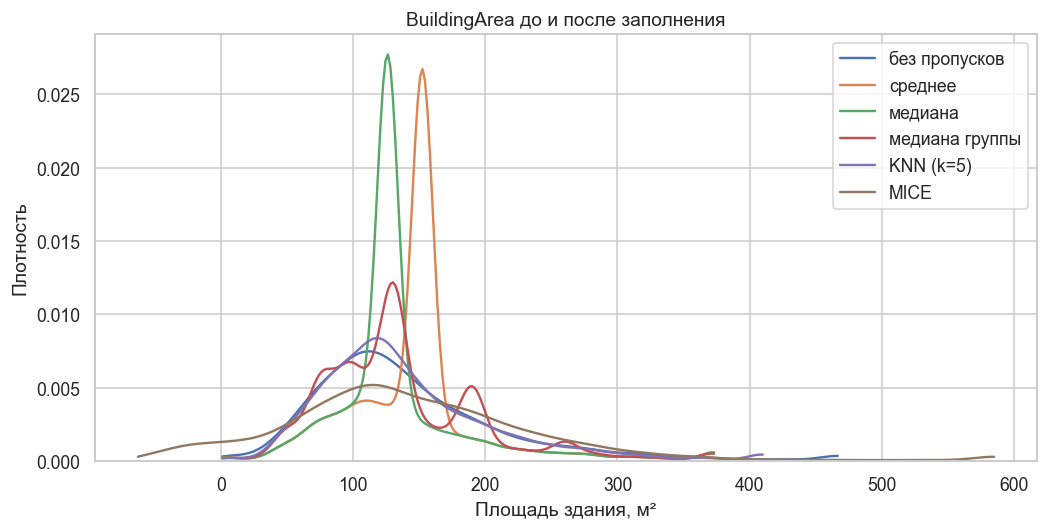

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
for name, values in variants.items():
    sns.kdeplot(values.clip(upper=values.quantile(0.99)), ax=ax, label=name, cut=0)
ax.legend()
ax.set(
    title='BuildingArea до и после заполнения',
    xlabel='Площадь здания, м²',
    ylabel='Плотность',
)
plt.show()

**Вывод по BuildingArea.** Заполнение средним сохраняет 152,3 м² в качестве
среднего, но снижает стандартное отклонение с 541,6 до 392,0 м². Глобальная
медиана снижает стандартное отклонение до 392,2 м². Оба способа дают узкий пик
в KDE. Групповая медиана сохраняет квартили ближе к наблюдаемым (96 и 166 м²
против 93 и 174 м²) и распределяет заполнения по нескольким типичным площадям.
KNN также сохраняет близкие квартили (95 и 170 м²). У MICE в этой реализации
получились отрицательная площадь (минимум −63,1 м²) и максимум 110 300,3 м².

Выбираем медиану по типу и числу комнат по её устойчивости к большим площадям
и интерпретируемости. Флаг сохраняет информацию о том, где площадь была
неизвестна. Для KDE верхний 1 % значений каждого варианта ограничен его
99-м процентилем только для показа. Статистики рассчитаны по полным данным.

### Категориальный признак CouncilArea

Сравниваем заполнение общей модой, категорией `Unknown` и модой по пригороду.
Для последнего варианта при отсутствии известного муниципалитета в пригороде используем `Unknown`.

,исходный,общая мода,Unknown,мода по Suburb
Муниципалитет,,,,
Moreland,8.56,18.65,8.56,9.19
Boroondara,8.54,8.54,8.54,9.41
Moonee Valley,7.34,7.34,7.34,7.94
Darebin,6.88,6.88,6.88,7.41
Glen Eira,6.24,6.24,6.24,6.62
Stonnington,5.29,5.29,5.29,5.60
Пропуск,10.08,0.00,0.00,0.00
Unknown,0.00,0.00,10.08,0.05


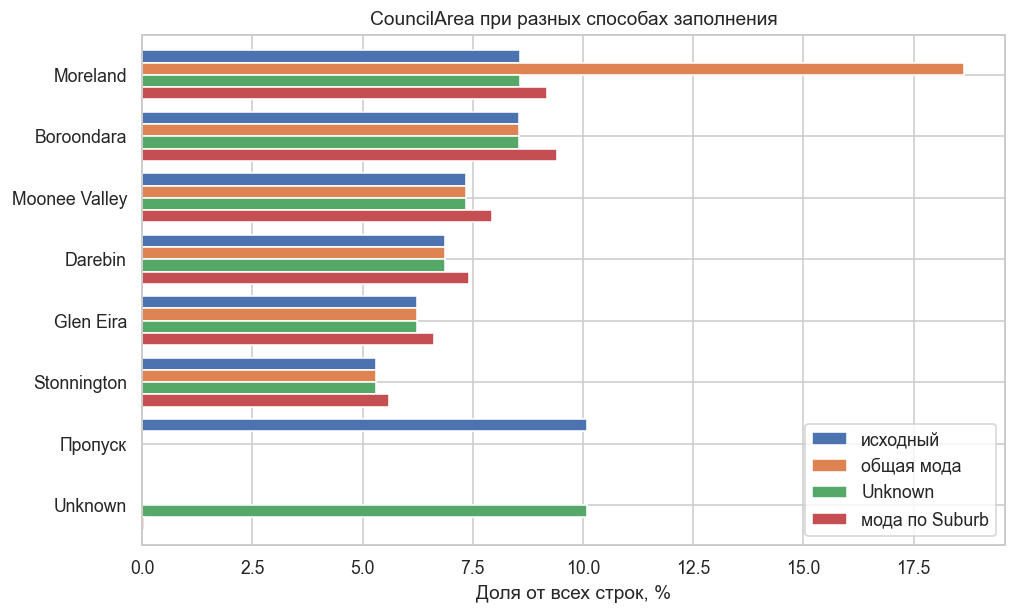

In [11]:
mode_by_suburb = df.groupby('Suburb')['CouncilArea'].agg(
    lambda values: values.mode().iloc[0] if values.notna().any() else np.nan
)
local_mode = df['Suburb'].map(mode_by_suburb)
global_mode = df['CouncilArea'].mode().iloc[0]
cat_variants = {
    'исходный': df['CouncilArea'],
    'общая мода': df['CouncilArea'].fillna(global_mode),
    'Unknown': df['CouncilArea'].fillna('Unknown'),
    'мода по Suburb': df['CouncilArea'].fillna(local_mode).fillna('Unknown'),
}
freq = pd.DataFrame({
    name: series.fillna('Пропуск').value_counts(normalize=True)
    for name, series in cat_variants.items()
}).fillna(0)
top = freq.drop(index=['Пропуск', 'Unknown']).nlargest(6, 'исходный').index.tolist()
top += ['Пропуск', 'Unknown']
freq_show = (freq.loc[top] * 100).rename_axis('Муниципалитет')
display(freq_show.round(2))

ax = freq_show.plot.barh(figsize=(9, 5.5), width=0.8)
ax.invert_yaxis()
ax.set(title='CouncilArea при разных способах заполнения', xlabel='Доля от всех строк, %', ylabel='')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [12]:
missing_council = df['CouncilArea'].isna()
known_council = ~missing_council
local_agreement = df.loc[known_council, 'CouncilArea'].eq(local_mode.loc[known_council]).mean()

pd.Series({
    'Пригородов с >1 известным муниципалитетом': (
        df.groupby('Suburb')['CouncilArea'].nunique().gt(1).sum()
    ),
    'Совпадение с локальной модой среди известных, %': round(100 * local_agreement, 2),
    'Пропусков с доступной модой по пригороду': (missing_council & local_mode.notna()).sum(),
    'Пропусков без моды по пригороду': (missing_council & local_mode.isna()).sum(),
}, name='Значение').to_frame()

,Значение
Пригородов с >1 известным муниципалитетом,29.00
"Совпадение с локальной модой среди известных, %",97.67
Пропусков с доступной модой по пригороду,1362.00
Пропусков без моды по пригороду,7.00


**Вывод по CouncilArea.** Глобальная мода повышает долю Moreland с 8,56 %
до 18,65 %. При заполнении константой все 10,08 % пропусков превращаются
в `Unknown`. Мода по пригороду даёт значение для 1 362 записей из 1 369.
Оставшиеся 7 записей (0,05 % выборки) получают `Unknown`. Доля Moreland
при этом достигает 9,19 %, а Boroondara — 9,41 %.

Среди известных значений 97,67 % совпадают с модой своего пригорода. В 29
пригородах встречается больше одного муниципалитета, поэтому это правило
может ошибаться. Процент совпадения рассчитан на тех же известных данных,
по которым найдена мода. Для итогового набора выбираем моду по пригороду
с резервной категорией `Unknown`.

In [13]:
for col in ['BuildingArea', 'YearBuilt']:
    df[col + '_was_na'] = df[col].isna().astype(int)

yb_sub = df.groupby('Suburb')['YearBuilt'].transform('median')
car_median = df['Car'].median()
yb_median = df['YearBuilt'].median()

fill_report = pd.DataFrame({
    'Заполнено всего': miss_count,
    'По группе': {
        'BuildingArea': (base.isna() & group_med.notna()).sum(),
        'YearBuilt': (df['YearBuilt'].isna() & yb_sub.notna()).sum(),
        'CouncilArea': (missing_council & local_mode.notna()).sum(),
        'Car': 0,
    },
})
fill_report['Общая статистика или Unknown'] = fill_report['Заполнено всего'] - fill_report['По группе']

df['Car'] = df['Car'].fillna(car_median)
df['BuildingArea'] = variants['медиана группы']
df['YearBuilt'] = df['YearBuilt'].fillna(yb_sub).fillna(yb_median)
df['CouncilArea'] = cat_variants['мода по Suburb']

print(f'Медиана Car: {car_median:g}, общая медиана YearBuilt: {yb_median:g}')
print(f"Осталось пропусков: {df.isna().sum().sum()}")
display(fill_report)

Медиана Car: 2, общая медиана YearBuilt: 1970
Осталось пропусков: 0


,Заполнено всего,По группе,Общая статистика или Unknown
BuildingArea,6467,6465,2
YearBuilt,5376,5358,18
CouncilArea,1369,1362,7
Car,62,0,62


## 2.5 Исследование распределений числовых признаков

Для `Price` и положительных значений `Landsize` проверяем гипотезу о логнормальном
распределении. При этой гипотезе $\ln X$ имеет нормальное распределение. Сопоставляем
Q–Q-графики до и после логарифмирования, оцениваем асимметрию и эксцесс и применяем
тест Д’Агостино–Пирсона к $\ln X$ при уровне значимости $\alpha=0{,}05$.

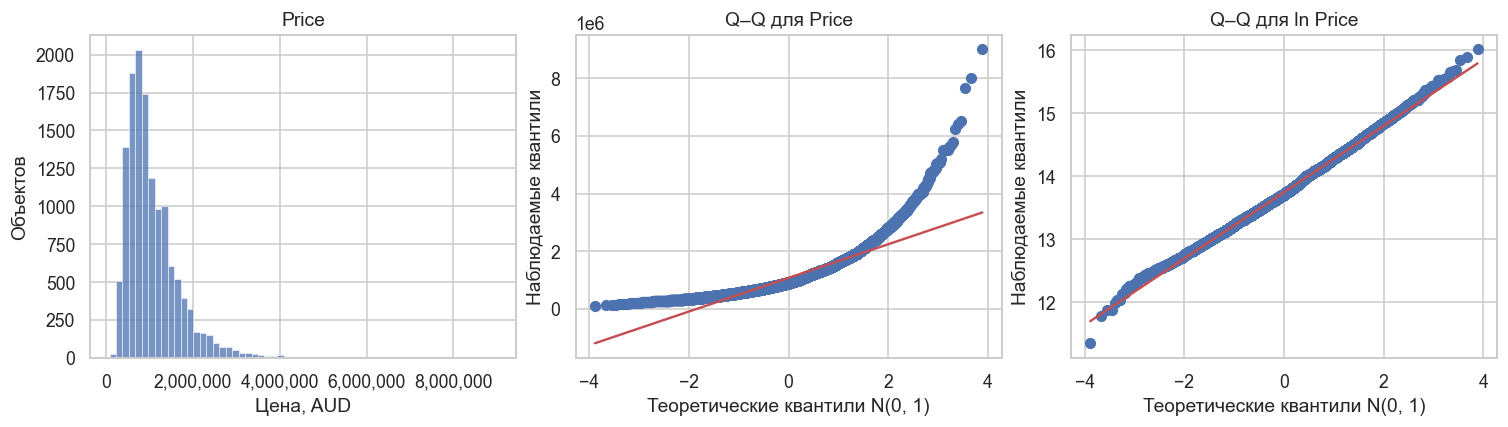

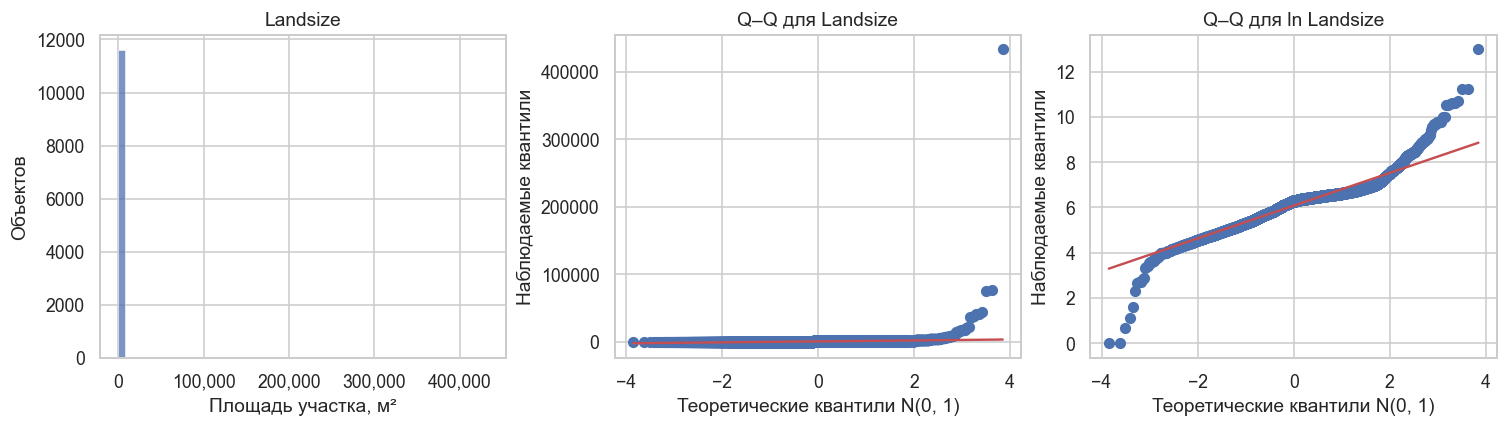

,N > 0,Исключено X ≤ 0,Асимметрия X,Эксцесс X,Асимметрия ln X,Эксцесс ln X,K² для ln X,p-значение
Price,13580.0,0.0,2.239377,9.870262,0.180640,0.005761,72.790276,1.562400e-16
Landsize,11641.0,1939.0,88.535379,8772.665524,0.008164,4.198291,1114.033825,1.232051e-242


In [14]:
def dist_report(series, name, unit):
    observed = series.dropna()
    positive = observed[observed.gt(0)]
    log_values = np.log(positive)

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), layout='constrained')
    sns.histplot(positive, ax=axes[0], bins=60)
    axes[0].set(title=name, xlabel=unit, ylabel='Объектов')
    axes[0].xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    for ax, values, label in zip(axes[1:], [positive, log_values], [name, f'ln {name}']):
        stats.probplot(values, dist='norm', plot=ax)
        ax.set(
            title=f'Q–Q для {label}',
            xlabel='Теоретические квантили N(0, 1)',
            ylabel='Наблюдаемые квантили',
        )
    plt.show()

    normality = stats.normaltest(log_values)
    return {
        'N > 0': len(positive),
        'Исключено X ≤ 0': len(observed) - len(positive),
        'Асимметрия X': stats.skew(positive),
        'Эксцесс X': stats.kurtosis(positive),
        'Асимметрия ln X': stats.skew(log_values),
        'Эксцесс ln X': stats.kurtosis(log_values),
        'K² для ln X': normality.statistic,
        'p-значение': normality.pvalue,
    }


dist_results = pd.DataFrame({
    'Price': dist_report(df['Price'], 'Price', 'Цена, AUD'),
    'Landsize': dist_report(df['Landsize'], 'Landsize', 'Площадь участка, м²'),
}).T
dist_results

**Вывод по Price.** После логарифмирования асимметрия падает с 2,24 до 0,18,
а эксцесс — с 9,87 до 0,006. На Q–Q-графике основная часть точек близка
к прямой, отклонения сохраняются на концах. Логнормальное распределение
служит приближением, хотя тест отвергает точное соответствие
($p=1{,}56\cdot10^{-16}$).

**Вывод по Landsize.** Логарифмирование положительных площадей снижает
асимметрию с 88,54 до 0,008. На Q–Q-графике логарифмов оба хвоста
отклоняются от прямой, а эксцесс остаётся 4,20. Тест отвергает
логнормальность даже для положительной части ($p=1{,}23\cdot10^{-242}$).
Ещё 1 939 нулевых площадей исключены только из этой проверки, поскольку
$\ln 0$ не определён.

## 2.6 Обнаружение выбросов

### 2.6.1 Правило трёх сигм

Используем интервал $\bar{x}\pm3s$. Для логарифмического варианта оцениваем $\bar{\ell}$ и $s_\ell$
по положительным значениям $\ell=\ln x$ и переносим границы в исходную шкалу
$[\exp(\bar{\ell}-3s_\ell), \exp(\bar{\ell}+3s_\ell)]$.

### 2.6.2 Метод межквартильного размаха

При $IQR=Q_3-Q_1$ используем интервал $[Q_1-K\cdot IQR, Q_3+K\cdot IQR]$ и сравниваем
$K=1{,}5$ и $K=3$.

### 2.6.3 Квантильный подход

Выделяем значения ниже 5-го и выше 95-го процентиля. Значения на самих границах
остаются внутри интервала.

### 2.6.4 Сравнение методов

Границы в таблице показаны в исходных единицах. По примеру из гайда каждую пару
границ применяем ко всем строкам, включая нулевые `Landsize`. Для метода $3\sigma$ на
логарифмах нули не участвуют в оценке границ и попадают под положительную нижнюю границу.

In [15]:
def bounds(values, method):
    if method == '3σ':
        mean, std = values.mean(), values.std()
        return mean - 3 * std, mean + 3 * std
    if method == '3σ на ln':
        logged = np.log(values[values.gt(0)])
        mean, std = logged.mean(), logged.std()
        return np.exp(mean - 3 * std), np.exp(mean + 3 * std)
    if method == 'Квантили 5–95%':
        return tuple(values.quantile([0.05, 0.95]))

    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    k = {'IQR, K=1.5': 1.5, 'IQR, K=3': 3}[method]
    return q1 - k * iqr, q3 + k * iqr


methods = ['3σ', '3σ на ln', 'IQR, K=1.5', 'IQR, K=3', 'Квантили 5–95%']
out_cols = ['Price', 'Landsize']
rows, masks = [], {}
for col in out_cols:
    values = df[col]
    for method in methods:
        lo, hi = bounds(values, method)
        below, above = values.lt(lo), values.gt(hi)
        mask = below | above
        masks[(col, method)] = mask
        rows.append([col, method, lo, hi, below.sum(), above.sum(), mask.sum(), mask.mean() * 100])

out_table = pd.DataFrame(rows, columns=[
    'Признак', 'Метод', 'Нижняя граница', 'Верхняя граница', 'Ниже', 'Выше', 'Всего', 'Доля, %',
])
out_table.round(2)

,Признак,Метод,Нижняя граница,Верхняя граница,Ниже,Выше,Всего,"Доля, %"
0,Price,3σ,-842248.09,2993616.25,0,232,232,1.71
1,Price,3σ на ln,191955.01,4527748.08,10,31,41,0.30
2,Price,"IQR, K=1.5",-370000.00,2350000.00,0,612,612,4.51
3,Price,"IQR, K=3",-1390000.00,3370000.00,0,132,132,0.97
4,Price,Квантили 5–95%,405000.00,2290050.00,671,679,1350,9.94
5,Landsize,3σ,-11413.59,12530.42,0,24,24,0.18
6,Landsize,3σ на ln,46.27,4087.21,1967,93,2060,15.17
7,Landsize,"IQR, K=1.5",-534.00,1362.00,0,368,368,2.71
8,Landsize,"IQR, K=3",-1245.00,2073.00,0,221,221,1.63
9,Landsize,Квантили 5–95%,0.00,995.00,0,678,678,4.99


Совпадение множеств отмеченных наблюдений оцениваем коэффициентом Жаккара
$J(A,B)=|A\cap B|/|A\cup B|$.

Price


,3σ,3σ на ln,"IQR, K=1.5","IQR, K=3",Квантили 5–95%
3σ,1.00,0.13,0.38,0.57,0.17
3σ на ln,0.13,1.00,0.05,0.22,0.03
"IQR, K=1.5",0.38,0.05,1.00,0.22,0.45
"IQR, K=3",0.57,0.22,0.22,1.00,0.10
Квантили 5–95%,0.17,0.03,0.45,0.10,1.00


Landsize


,3σ,3σ на ln,"IQR, K=1.5","IQR, K=3",Квантили 5–95%
3σ,1.00,0.01,0.07,0.11,0.04
3σ на ln,0.01,1.00,0.04,0.04,0.04
"IQR, K=1.5",0.07,0.04,1.00,0.60,0.54
"IQR, K=3",0.11,0.04,0.60,1.00,0.33
Квантили 5–95%,0.04,0.04,0.54,0.33,1.00


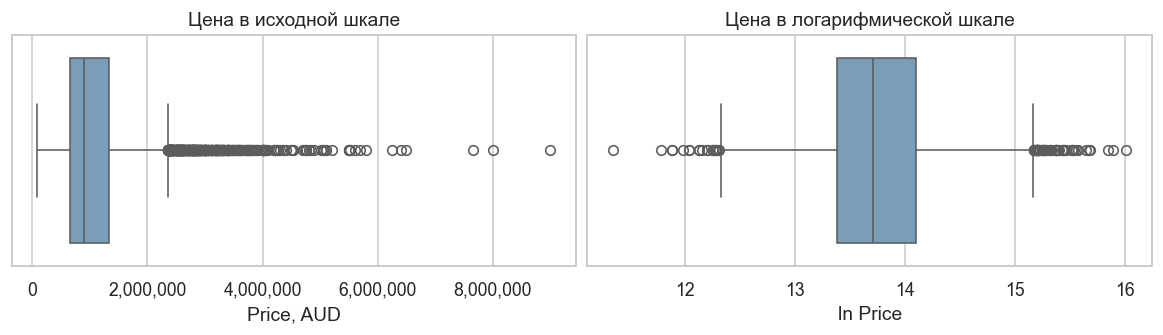

In [16]:
def jaccard(a, b):
    return (a & b).sum() / max((a | b).sum(), 1)


for col in out_cols:
    print(col)
    overlap = pd.DataFrame(
        [[jaccard(masks[(col, a)], masks[(col, b)]) for b in methods] for a in methods],
        index=methods,
        columns=methods,
    )
    display(overlap.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), layout='constrained')
sns.boxplot(x=df['Price'], ax=axes[0], color='#6fa0c3')
sns.boxplot(x=np.log(df['Price']), ax=axes[1], color='#6fa0c3')
axes[0].set(title='Цена в исходной шкале', xlabel='Price, AUD')
axes[0].xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axes[1].set(title='Цена в логарифмической шкале', xlabel='ln Price')
plt.show()

In [17]:
sale_cols = ['Suburb', 'Address', 'Type', 'Rooms', 'Price', 'Landsize', 'BuildingArea']
print(f"Сделок дороже 5 млн AUD: {df['Price'].gt(5_000_000).sum()}")
display(df.nlargest(5, 'Price')[sale_cols])
display(df.nlargest(5, 'Landsize')[sale_cols])

Сделок дороже 5 млн AUD: 21


,Suburb,Address,Type,Rooms,Price,Landsize,BuildingArea
12094,Mulgrave,35 Bevis St,h,3,9000000.0,744.0,117.0
7692,Canterbury,49 Mangarra Rd,h,5,8000000.0,2079.0,464.3
9575,Hawthorn,49 Lisson Gr,h,4,7650000.0,1690.0,284.0
3616,Kew,15 Barry St,h,6,6500000.0,1334.0,365.0
12557,Middle Park,136 Page St,h,5,6400000.0,553.0,308.0


,Suburb,Address,Type,Rooms,Price,Landsize,BuildingArea
11020,Fitzroy,389 Gore St,h,3,2700000.0,433014.0,130.0
10504,Silvan,16 Eleanor Dr,h,3,1085000.0,76000.0,130.0
687,Balwyn North,9 Gildan St,h,3,2000000.0,75100.0,130.0
13245,New Gisborne,71 Hamilton Rd,h,5,1355000.0,44500.0,44515.0
5194,Reservoir,14 Beenak St,h,3,572000.0,41400.0,130.0


**Вывод.** На исходной шкале правило трёх сигм даёт отрицательные нижние
границы и отмечает только верхний хвост: 232 цены и 24 площади участка.
Крайние значения увеличивают среднее и стандартное отклонение. Границы
IQR опираются на центральную половину выборки. Для `Landsize` IQR при
$K=1{,}5$ отмечает 368 строк, при $K=3$ — 221 строку. Второе множество
вложено в первое ($J=0{,}60$).

Для `Price` три сигмы на логарифмах выделяют 10 низких и 31 высокую цену.
Пересечение с исходным правилом даёт $J=0{,}13$. Для `Landsize` этот
вариант выделяет 2 060 строк, среди которых 1 939 нулей. Поэтому его
результат сильно расходится с IQR при $K=3$ ($J=0{,}04$). Квантильный
метод отмечает 9,94 % цен и 4,99 % площадей. У площади 5-й процентиль
равен нулю, поэтому метод выделил только верхний хвост.

В выборке 21 сделка дороже 5 млн AUD. Высокая цена сама по себе допустима
для редких сделок, поэтому сохраняем исходные цены. Участок 433 014 м²
у трёхкомнатного дома в Fitzroy выглядит необычно. Возможны ошибка ввода
или площадь всего комплекса. Для больших участков ограничиваем влияние
верхнего хвоста единым порогом, сохраняя соответствующие сделки.

## 2.7 Обработка выбросов

Исходные цены сохраняем. При моделировании можно использовать $\ln(Price)$, чтобы
сжать правый хвост. `Landsize` винзоризируем по верхней границе IQR при $K=3$.
Нижнюю границу ставим на 0, чтобы сохранить значения для объектов без собственного участка.

In [18]:
land_before = df['Landsize'].copy()
_, hi = bounds(land_before, 'IQR, K=3')
df['Landsize'] = land_before.clip(lower=0, upper=hi)
clipped = df['Landsize'].ne(land_before)

print(f'Верхняя граница: {hi:g} м²')
print(f'Изменено значений: {clipped.sum()} ({clipped.mean():.2%})')
print(f"На верхней границе до: {land_before.eq(hi).sum()}, после: {df['Landsize'].eq(hi).sum()}")
pd.DataFrame({'До': land_before.describe(), 'После': df['Landsize'].describe()}).round(2)

Верхняя граница: 2073 м²
Изменено значений: 221 (1.63%)
На верхней границе до: 0, после: 221


,До,После
count,13580.00,13580.00
mean,558.42,455.60
std,3990.67,376.68
min,0.00,0.00
25%,177.00,177.00
50%,440.00,440.00
75%,651.00,651.00
max,433014.00,2073.00


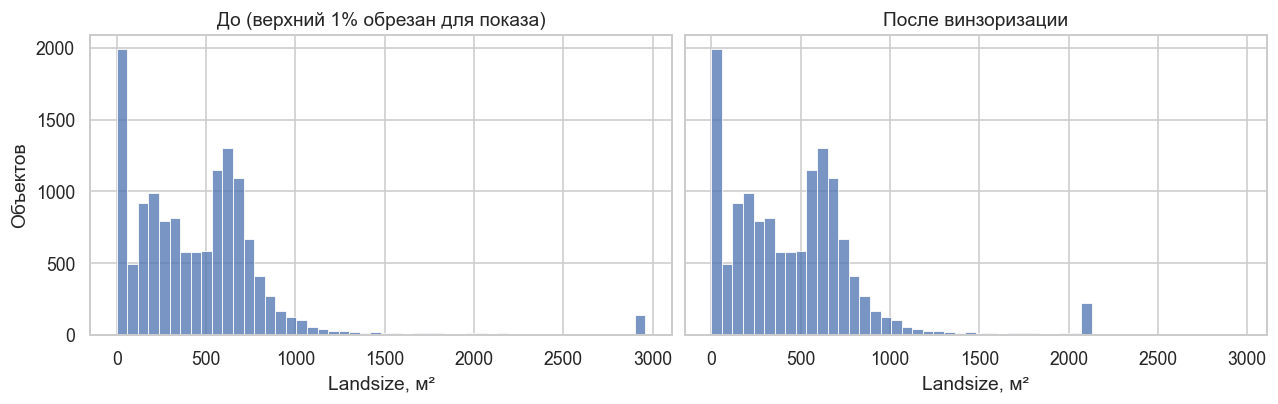

In [19]:
q99 = land_before.quantile(0.99)
bin_edges = np.linspace(0, max(q99, hi), 51)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True, layout='constrained')
sns.histplot(land_before.clip(upper=q99), ax=axes[0], bins=bin_edges)
sns.histplot(df['Landsize'], ax=axes[1], bins=bin_edges)
axes[0].set(title='До (верхний 1% обрезан для показа)', ylabel='Объектов')
axes[1].set(title='После винзоризации', ylabel='')
for ax in axes:
    ax.set_xlabel('Landsize, м²')
plt.show()

**Вывод.** Винзоризация заменила 221 значение `Landsize` (1,63 %) на
2 073 м². Среднее снизилось с 558,42 до 455,60 м², стандартное отклонение —
с 3 990,67 до 376,68 м². Медиана (440 м²) и квартили (177 и 651 м²)
сохранились. На границе возник пик из 221 значения. После замены
различия между участками выше порога больше не видны, но все строки
сделок сохранены.

## 2.8 Сравнение исходного и обработанного наборов данных

In [20]:
summary = pd.DataFrame({
    'Пропусков до': df_raw.isna().sum(),
    'Пропусков после': df[df_raw.columns].isna().sum(),
    'Среднее до': df_raw[num_cols].mean(),
    'Среднее после': df[num_cols].mean(),
    'Std до': df_raw[num_cols].std(),
    'Std после': df[num_cols].std(),
}).round(2)

shape_report = pd.DataFrame({
    'До': [len(df_raw), df_raw.shape[1], df_raw.isna().sum().sum()],
    'После': [len(df), df.shape[1], df.isna().sum().sum()],
}, index=['Строки', 'Столбцы', 'Пропущенные значения'])
display(shape_report)
summary.astype(object).fillna('—')

,До,После
Строки,13580,13580
Столбцы,21,23
Пропущенные значения,13256,0


,Пропусков до,Пропусков после,Среднее до,Среднее после,Std до,Std после
Address,0,0,—,—,—,—
Bathroom,0,0,1.53,1.53,0.69,0.69
Bedroom2,0,0,2.91,2.91,0.97,0.97
BuildingArea,6450,0,151.97,141.68,541.01,393.53
Car,62,0,1.61,1.61,0.96,0.96
CouncilArea,1369,0,—,—,—,—
Date,0,0,—,—,—,—
Distance,0,0,10.14,10.14,5.87,5.87
Landsize,0,0,558.42,455.6,3990.67,376.68
Lattitude,0,0,-37.81,-37.81,0.08,0.08


In [21]:
clean_path = data_dir / 'melb_clean.csv'
df.to_csv(clean_path, index=False)
print(f'Итоговый набор данных сохранён в {clean_path.name}.')

Итоговый набор данных сохранён в melb_clean.csv.


**Итоговый вывод.** Заполнено 13 274 значения, включая 18 значений,
переведённых в пропуски при первичной проверке. Из них 62 значения
`Car` заполнены общей медианой, 6 467 значений `BuildingArea` —
групповой медианой с резервом на общую, 5 376 значений `YearBuilt` —
медианой пригорода с таким же резервом. Для `CouncilArea` 1 362 значения
восстановлены модой пригорода, 7 обозначены `Unknown`.

Все 13 580 строк сохранены, поскольку удаление неполных строк привело бы
к потере 54,39 % записей и изменило бы состав выборки. В `melb_clean.csv`
23 столбца, включая два флага пропуска, и нет пустых значений. После
заполнения средняя `BuildingArea` снизилась с 151,97 до 141,68 м²,
стандартное отклонение — с 541,01 до 393,53 м². У `YearBuilt` стандартное
отклонение снизилось с 37,27 до 30,97 года. Винзоризация ограничила
221 площадь участка и сократила её разброс. Статистики целевой цены
совпадают с исходными.